In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv('Pakistan Largest Ecommerce Dataset.csv')

C:\Users\Refaat2\AppData\Local\Temp\ipykernel_20408\3463096870.py:1: DtypeWarning: Columns (1,2,3,7,8,9,11,12,13,14,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Pakistan Largest Ecommerce Dataset.csv')


In [3]:
df_raw = df.copy()

In [154]:
#Item_id: Just an index because whne the same item is appears again it give it a different item_id 
#Created_at : DAte the order was placed
#sku: Product code/Name unique for each item
#Price: IS beforw the discount
#incremnet_id: Order_ID
#Working_Date: The data the order was processed
#BI_Status: Net/Gross/Valid
#Other columns are known

In [4]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,1048565,1048566,1048567,1048568,1048569,1048570,1048571,1048572,1048573,1048574
item_id,211131.0,211133.0,211134.0,211135.0,211136.0,211137.0,211138.0,211139.0,211140.0,211141.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,complete,canceled,canceled,complete,order_refunded,canceled,complete,complete,canceled,canceled,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,7/1/2016,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sku,kreations_YI 06-L,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,Ego_UP0017-999-MR0,kcc_krone deal,BK7010400AG,UK_Namkino All In One 200 Gms,kcc_krone deal,UK_Namkino Mix Nimco 400 Gms,Apple iPhone 6S 64GB,Apple iPhone 6S 64GB,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,1950.0,240.0,2450.0,360.0,555.0,80.0,360.0,170.0,96499.0,96499.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qty_ordered,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grand_total,1950.0,240.0,2450.0,60.0,1110.0,80.0,60.0,170.0,96499.0,96499.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
increment_id,100147443,100147444,100147445,100147446,100147447,100147448,100147449,100147450,100147451,100147452,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_name_1,Women's Fashion,Beauty & Grooming,Women's Fashion,Beauty & Grooming,Soghaat,Soghaat,Beauty & Grooming,Soghaat,Mobiles & Tablets,Mobiles & Tablets,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_commission_code,\N,\N,\N,R-FSD-52352,\N,\N,\N,\N,\N,\N,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-

In [6]:
df.describe()

,item_id,price,qty_ordered,grand_total,discount_amount,Year,Month,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
count,584524.000000,5.845240e+05,584524.000000,5.845240e+05,584524.000000,584524.000000,584524.000000,584513.000000,0.0,0.0,0.0,0.0,0.0
mean,565667.074218,6.348748e+03,1.296388,8.530619e+03,499.492775,2017.044115,7.167654,45790.511965,NaN,NaN,NaN,NaN,NaN
std,200121.173648,1.494927e+04,3.996061,6.132081e+04,1506.943046,0.707355,3.486305,34414.962389,NaN,NaN,NaN,NaN,NaN
min,211131.000000,0.000000e+00,1.000000,-1.594000e+03,-599.500000,2016.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN
25%,395000.750000,3.600000e+02,1.000000,9.450000e+02,0.000000,2017.000000,4.000000,13516.000000,NaN,NaN,NaN,NaN,NaN
50%,568424.500000,8.990000e+02,1.000000,1.960400e+03,0.000000,2017.000000,7.000000,42856.000000,NaN,NaN,NaN,NaN,NaN
75%,739106.250000,4.070000e+03,1.000000,6.999000e+03,160.500000,2018.000000,11.000000,73536.000000,NaN,NaN,NaN,NaN,NaN
max,905208.000000,1.012626e+06,1000.000000,1.788800e+07,90300.000000,2018.000000,12.000000,115326.000000,NaN,NaN,NaN,NaN,NaN


In [7]:
df.describe(include='object')

,status,created_at,sku,increment_id,category_name_1,sales_commission_code,payment_method,Working Date,BI Status,MV,Customer Since,M-Y,FY
count,584509,584524,584504,584524,584360,447346,584524,584524,584524,584524,584513,584524,584524
unique,16,789,84889,408785,16,7225,18,789,4,9720,26,26,3
top,complete,11/25/2016,MATSAM59DB75ADB2F80,100266667,Mobiles & Tablets,\N,cod,11/25/2016,Net,999,2016-11,11-2017,FY18
freq,233685,15169,3775,72,115710,339001,271960,15169,234178,9516,82714,83928,306883


In [8]:
df.isnull().sum() * 100/len(df)

item_id                   44.255394
status                    44.256825
created_at                44.255394
sku                       44.257302
price                     44.255394
qty_ordered               44.255394
grand_total               44.255394
increment_id              44.255394
category_name_1           44.271034
sales_commission_code     57.337720
discount_amount           44.255394
payment_method            44.255394
Working Date              44.255394
BI Status                 44.255394
 MV                       44.255394
Year                      44.255394
Month                     44.255394
Customer Since            44.256443
M-Y                       44.255394
FY                        44.255394
Customer ID               44.256443
Unnamed: 21              100.000000
Unnamed: 22              100.000000
Unnamed: 23              100.000000
Unnamed: 24              100.000000
Unnamed: 25              100.000000
dtype: float64

In [9]:
df = df.drop(columns=['Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23','Unnamed: 24', 'Unnamed: 25'])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-

In [11]:
df.duplicated().sum()

np.int64(464050)

In [12]:
df = df.drop_duplicates()

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 584525 entries, 0 to 584524
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  float64
 1   status                 584509 non-null  object 
 2   created_at             584524 non-null  object 
 3   sku                    584504 non-null  object 
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  float64
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  object 
 8   category_name_1        584360 non-null  object 
 9   sales_commission_code  447346 non-null  object 
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  object 
 12  Working Date           584524 non-null  object 
 13  BI Status              584524 non-null  object 
 14   MV                    584524 non-null  o

In [14]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working Date', 'BI Status', ' MV ', 'Year', 'Month', 'Customer Since',
       'M-Y', 'FY', 'Customer ID'],
      dtype='object')

In [15]:
df = df.rename(columns={' MV ': 'MV'})

In [16]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working Date', 'BI Status', 'MV', 'Year', 'Month', 'Customer Since',
       'M-Y', 'FY', 'Customer ID'],
      dtype='object')

In [17]:
df = df.rename(columns={'Working Date': 'Working_Date'})

In [18]:
df = df.rename(columns={'BI Status': 'BI_Status'})

In [19]:
df = df.rename(columns={'Customer Since': 'Customer_Since'})

In [20]:
df = df.rename(columns={'Customer ID': 'Customer_ID'})

In [21]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working_Date', 'BI_Status', 'MV', 'Year', 'Month', 'Customer_Since',
       'M-Y', 'FY', 'Customer_ID'],
      dtype='object')

In [22]:
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')

In [23]:
df['Working_Date'] = pd.to_datetime(df['Working_Date'], errors='coerce')

In [24]:
df['Year'] = df['Year'].astype('Int64')

In [25]:
df['Month'] = df['Month'].astype('Int64')

In [26]:
df['Customer_Since'] = pd.to_datetime(df['Customer_Since'], format='%Y-%m', errors='coerce').dt.to_period('M')

In [27]:
df['M-Y'] = pd.to_datetime(df['M-Y'], format='%m-%Y', errors='coerce').dt.to_period('M')

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 584525 entries, 0 to 584524
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   item_id                584524 non-null  float64       
 1   status                 584509 non-null  object        
 2   created_at             584524 non-null  datetime64[ns]
 3   sku                    584504 non-null  object        
 4   price                  584524 non-null  float64       
 5   qty_ordered            584524 non-null  float64       
 6   grand_total            584524 non-null  float64       
 7   increment_id           584524 non-null  object        
 8   category_name_1        584360 non-null  object        
 9   sales_commission_code  447346 non-null  object        
 10  discount_amount        584524 non-null  float64       
 11  payment_method         584524 non-null  object        
 12  Working_Date           584524 non-null  datetime6

In [29]:
df['MV'].value_counts()

MV
999         9516
699         7801
499         7157
1,000       6895
399         6506
            ... 
43,100         1
177,916        1
74,486         1
37,243         1
39,399         1
Name: count, Length: 9720, dtype: int64

In [30]:
df['MV'].head(20)

0       1,950 
1         240 
2       2,450 
3         360 
4       1,110 
5          80 
6         360 
7         170 
8      96,499 
9      96,499 
10      5,500 
11        210 
12        156 
13        120 
14        320 
15      1,550 
16        420 
17        360 
18        490 
19        899 
Name: MV, dtype: object

In [31]:
df['MV'] = df['MV'].str.replace(',','', regex=False)

In [32]:
df['MV'].head(20)

0       1950 
1        240 
2       2450 
3        360 
4       1110 
5         80 
6        360 
7        170 
8      96499 
9      96499 
10      5500 
11       210 
12       156 
13       120 
14       320 
15      1550 
16       420 
17       360 
18       490 
19       899 
Name: MV, dtype: object

In [33]:
df['MV'] = pd.to_numeric(df['MV'], errors='coerce').astype('Int64')

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 584525 entries, 0 to 584524
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   item_id                584524 non-null  float64       
 1   status                 584509 non-null  object        
 2   created_at             584524 non-null  datetime64[ns]
 3   sku                    584504 non-null  object        
 4   price                  584524 non-null  float64       
 5   qty_ordered            584524 non-null  float64       
 6   grand_total            584524 non-null  float64       
 7   increment_id           584524 non-null  object        
 8   category_name_1        584360 non-null  object        
 9   sales_commission_code  447346 non-null  object        
 10  discount_amount        584524 non-null  float64       
 11  payment_method         584524 non-null  object        
 12  Working_Date           584524 non-null  datetime6

In [35]:
df['increment_id'] = pd.to_numeric(df['increment_id'], errors='coerce').astype('Int64')

In [36]:
df['item_id'] = df['item_id'].astype('Int64')

In [37]:
df['Customer_ID'] = df['Customer_ID'].astype('Int64')

In [38]:
df['qty_ordered'] = df['qty_ordered'].astype('Int64')

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 584525 entries, 0 to 584524
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   item_id                584524 non-null  Int64         
 1   status                 584509 non-null  object        
 2   created_at             584524 non-null  datetime64[ns]
 3   sku                    584504 non-null  object        
 4   price                  584524 non-null  float64       
 5   qty_ordered            584524 non-null  Int64         
 6   grand_total            584524 non-null  float64       
 7   increment_id           584515 non-null  Int64         
 8   category_name_1        584360 non-null  object        
 9   sales_commission_code  447346 non-null  object        
 10  discount_amount        584524 non-null  float64       
 11  payment_method         584524 non-null  object        
 12  Working_Date           584524 non-null  datetime6

In [40]:
df.isnull().sum() * 100/len(df)

item_id                   0.000171
status                    0.002737
created_at                0.000171
sku                       0.003593
price                     0.000171
qty_ordered               0.000171
grand_total               0.000171
increment_id              0.001711
category_name_1           0.028228
sales_commission_code    23.468457
discount_amount           0.000171
payment_method            0.000171
Working_Date              0.000171
BI_Status                 0.000171
MV                        0.382020
Year                      0.000171
Month                     0.000171
Customer_Since            0.002053
M-Y                       0.000171
FY                        0.000171
Customer_ID               0.002053
dtype: float64

In [41]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working_Date', 'BI_Status', 'MV', 'Year', 'Month', 'Customer_Since',
       'M-Y', 'FY', 'Customer_ID'],
      dtype='object')

In [42]:
drop_missing_columns = ['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1', 'discount_amount', 'payment_method',
       'Working_Date', 'BI_Status', 'MV', 'Year', 'Month', 'Customer_Since',
       'M-Y', 'FY', 'Customer_ID']

In [43]:
df = df.dropna(subset = drop_missing_columns)

In [44]:
df.isnull().sum() * 100/len(df)

item_id                   0.000000
status                    0.000000
created_at                0.000000
sku                       0.000000
price                     0.000000
qty_ordered               0.000000
grand_total               0.000000
increment_id              0.000000
category_name_1           0.000000
sales_commission_code    23.392391
discount_amount           0.000000
payment_method            0.000000
Working_Date              0.000000
BI_Status                 0.000000
MV                        0.000000
Year                      0.000000
Month                     0.000000
Customer_Since            0.000000
M-Y                       0.000000
FY                        0.000000
Customer_ID               0.000000
dtype: float64

In [45]:
df['sales_commission_code'].value_counts()

sales_commission_code
\N                     337929
40968                    2710
C-LHW-50074              2432
C-RWP-31924              1719
cisb30211                1613
                        ...  
GRS-4012863-3               1
GRS-4012863-4               1
R-uet-90402                 1
Voucher:COV_MJU6E73         1
CHDD100197                  1
Name: count, Length: 7224, dtype: int64

In [46]:
df.tail()

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID
584519,905204,cod,2018-08-28,WOFSCE5AE00357AECDE,699.0,1,849.0,100562385,Women's Fashion,NaN,...,cod,2018-08-28,Valid,699,2018,8,2018-08,2018-08,FY19,115320
584520,905205,processing,2018-08-28,MATHUA5AF70A7D1E50A,35599.0,1,35899.0,100562386,Mobiles & Tablets,NaN,...,bankalfalah,2018-08-28,Gross,35599,2018,8,2018-08,2018-08,FY19,115326
584521,905206,processing,2018-08-28,MATSAM5B6D7208C6D30,129999.0,2,652178.0,100562387,Mobiles & Tablets,NaN,...,bankalfalah,2018-08-28,Gross,259998,2018,8,2018-07,2018-08,FY19,113474
584522,905207,processing,2018-08-28,MATSAM5B1509B4696EA,87300.0,2,652178.0,100562387,Mobiles & Tablets,NaN,...,bankalfalah,2018-08-28,Gross,174600,2018,8,2018-07,2018-08,FY19,113474
584523,905208,processing,2018-08-28,MATSAM5B10F91A9B6AB,108640.0,2,652178.0,100562387,Mobiles & Tablets,NaN,...,bankalfalah,2018-08-28,Gross,217280,2018,8,2018-07,2018-08,FY19,113474


In [47]:
df['sales_commission_code'] = df['sales_commission_code'].replace('\\N', np.nan)

In [48]:
df['sales_commission_code'].value_counts()

sales_commission_code
40968                  2710
C-LHW-50074            2432
C-RWP-31924            1719
cisb30211              1613
R-GUJ-105814           1446
                       ... 
GRS-4012863-3             1
GRS-4012863-4             1
R-uet-90402               1
Voucher:COV_MJU6E73       1
CHDD100197                1
Name: count, Length: 7223, dtype: int64

In [49]:
df['sales_commission_code'] = df['sales_commission_code'].fillna('No Code')

In [50]:
df.isnull().sum() * 100/len(df)

item_id                  0.0
status                   0.0
created_at               0.0
sku                      0.0
price                    0.0
qty_ordered              0.0
grand_total              0.0
increment_id             0.0
category_name_1          0.0
sales_commission_code    0.0
discount_amount          0.0
payment_method           0.0
Working_Date             0.0
BI_Status                0.0
MV                       0.0
Year                     0.0
Month                    0.0
Customer_Since           0.0
M-Y                      0.0
FY                       0.0
Customer_ID              0.0
dtype: float64

In [51]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working_Date', 'BI_Status', 'MV', 'Year', 'Month', 'Customer_Since',
       'M-Y', 'FY', 'Customer_ID'],
      dtype='object')

In [52]:
df['status'].value_counts(dropna=False)

status
complete          233315
canceled          200380
received           76922
order_refunded     59022
refund              7864
cod                 2751
paid                1150
closed               493
payment_review        57
pending               48
processing            33
holded                31
fraud                 10
pending_paypal         7
\N                     4
exchange               4
Name: count, dtype: int64

In [53]:
df['status'] = df['status'].replace('\\N', np.nan)

In [54]:
df['status'].isnull().sum()

np.int64(4)

In [55]:
df = df.dropna(subset = ['status'])

In [56]:
df['status'].isnull().sum()

np.int64(0)

In [57]:
df['category_name_1'].value_counts()

category_name_1
Mobiles & Tablets     115394
Men's Fashion          91805
Women's Fashion        59485
Appliances             52321
Superstore             43439
Beauty & Grooming      41403
Soghaat                33999
Others                 29188
Home & Living          26404
Entertainment          26318
Health & Sports        17501
Kids & Baby            16441
Computing              15901
\N                      7818
School & Education      3478
Books                   1192
Name: count, dtype: int64

In [58]:
df['category_name_1'] = df['category_name_1'].replace('\\N', np.nan)

In [59]:
df['category_name_1'] = df['category_name_1'].fillna('Unknown')

In [60]:
df['category_name_1'].value_counts()

category_name_1
Mobiles & Tablets     115394
Men's Fashion          91805
Women's Fashion        59485
Appliances             52321
Superstore             43439
Beauty & Grooming      41403
Soghaat                33999
Others                 29188
Home & Living          26404
Entertainment          26318
Health & Sports        17501
Kids & Baby            16441
Computing              15901
Unknown                 7818
School & Education      3478
Books                   1192
Name: count, dtype: int64

In [61]:
df['BI_Status'].value_counts()

BI_Status
Net      233807
Gross    200566
Valid    147713
#REF!         1
Name: count, dtype: int64

In [62]:
df = df.drop(df[df['BI_Status'] == '#REF!'].index)

In [63]:
df['BI_Status'].value_counts()

BI_Status
Net      233807
Gross    200566
Valid    147713
Name: count, dtype: int64

In [64]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1',
       'sales_commission_code', 'discount_amount', 'payment_method',
       'Working_Date', 'BI_Status', 'MV', 'Year', 'Month', 'Customer_Since',
       'M-Y', 'FY', 'Customer_ID'],
      dtype='object')

In [65]:
df[(df['grand_total'] <= 0)].T

,14,24,27,28,266,313,523,556,622,651,...,584251,584252,584254,584255,584262,584263,584368,584405,584514,584515
item_id,211146,211157,211162,211163,211422,211472,211704,211743,211823,211854,...,904892,904893,904895,904896,904903,904904,905028,905080,905196,905198
status,complete,order_refunded,complete,complete,complete,complete,complete,order_refunded,complete,complete,...,paid,paid,paid,paid,paid,paid,paid,paid,paid,paid
created_at,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,...,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-28 00:00:00,2018-08-28 00:00:00
sku,kcc_glamour deal,D Lend a Helping Hand,SKMT_Blood Test,SKMT_Medicine,sstop_3dcreenwithspeakers,kcc_glamour deal,US-MSK-6-pink-2T,ajmery_BAT-3-S,sentiments_Ferrero Rocher Gift Box,audionic6-954217-562582,...,AL-5B2CDBFAE958C,VIT5AC4A6EB30D5C,BAGKEM5A8D45AB65E33,MEFDEA5AF92BE12A652,BAGDAF59FADB3EA33C9,MEFRED5B445E6B94853-S,ENTECO5A7FE80D6C830,MEFC-T5A79B6E8346D9-M,MEFGUL5A9F882AA5B99-36,MEFPAK5B360B03C6B72
price,320.0,1000.0,500.0,100.0,995.0,320.0,799.0,999.0,1.0,585.0,...,91.0,325.0,1750.0,1999.0,2085.0,837.0,20599.0,799.0,1299.0,999.0
qty_ordered,1,1,1,5,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
grand_total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
increment_id,100147456,100147461,100147463,100147463,100147648,100147686,100147867,100147896,100147952,100147977,...,100562210,100562210,100562212,100562213,100562219,100562219,100562284,100562301,100562381,100562381
category_name_1,Beauty & Grooming,Unknown,Others,Others,Computing,Beauty & Grooming,Kids & Baby,Men's Fashion,Unknown,Computing,...,Superstore,Superstore,Beauty & Grooming,Men's Fashion,Beauty & Grooming,Men's Fashion,Entertainment,Men's Fashion,Men's Fashion,Men's Fashion
sales_commission_code,No Code,No Code,No Code,No Code,No Code,C-MUX-20260,No Code,No Code,No Code,R-LHC-104412,...,No Code,No Code,GRS-4090974-1,GRS-4090975-1,No Code,No Code,R-GUJ-106946,No Code,No Code,No Code


In [66]:
df[(df['price'] <= 0)]

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID


In [67]:
df[(df['qty_ordered'] <= 0)]

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID


In [68]:
df[(df['discount_amount'] < 0)].T

,152474,152478,152479
item_id,403716,403730,403731
status,canceled,order_refunded,canceled
created_at,2017-02-13 00:00:00,2017-02-13 00:00:00,2017-02-13 00:00:00
sku,akl-GFSU1265-M,test-product,RB_HouseholdBundle
price,5995.0,4.0,1000.0
qty_ordered,1,2,5
grand_total,5395.5,156.0,4998.0
increment_id,100269243,100269252,100269253
category_name_1,Women's Fashion,Unknown,Superstore
sales_commission_code,No Code,No Code,No Code


In [69]:
df.head().T

,1,2,3,4,5
item_id,211133,211134,211135,211136,211137
status,canceled,canceled,complete,order_refunded,canceled
created_at,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00
sku,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,Ego_UP0017-999-MR0,kcc_krone deal,BK7010400AG,UK_Namkino All In One 200 Gms
price,240.0,2450.0,360.0,555.0,80.0
qty_ordered,1,1,1,2,1
grand_total,240.0,2450.0,60.0,1110.0,80.0
increment_id,100147444,100147445,100147446,100147447,100147448
category_name_1,Beauty & Grooming,Women's Fashion,Beauty & Grooming,Soghaat,Soghaat
sales_commission_code,No Code,No Code,R-FSD-52352,No Code,No Code


In [70]:
#grand_total is the total after applying the discount

In [71]:
df = df.drop(df[df['item_id'] == 403730].index)

In [72]:
df[(df['discount_amount'] < 0)].T

,152474,152479
item_id,403716,403731
status,canceled,canceled
created_at,2017-02-13 00:00:00,2017-02-13 00:00:00
sku,akl-GFSU1265-M,RB_HouseholdBundle
price,5995.0,1000.0
qty_ordered,1,5
grand_total,5395.5,4998.0
increment_id,100269243,100269253
category_name_1,Women's Fashion,Superstore
sales_commission_code,No Code,No Code


In [73]:
df['discount_amount'] = df['discount_amount'].abs()

In [74]:
df[(df['discount_amount'] < 0)]

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID


In [75]:
df[(df['grand_total'] <= 0)].T

,14,24,27,28,266,313,523,556,622,651,...,584251,584252,584254,584255,584262,584263,584368,584405,584514,584515
item_id,211146,211157,211162,211163,211422,211472,211704,211743,211823,211854,...,904892,904893,904895,904896,904903,904904,905028,905080,905196,905198
status,complete,order_refunded,complete,complete,complete,complete,complete,order_refunded,complete,complete,...,paid,paid,paid,paid,paid,paid,paid,paid,paid,paid
created_at,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,...,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-28 00:00:00,2018-08-28 00:00:00
sku,kcc_glamour deal,D Lend a Helping Hand,SKMT_Blood Test,SKMT_Medicine,sstop_3dcreenwithspeakers,kcc_glamour deal,US-MSK-6-pink-2T,ajmery_BAT-3-S,sentiments_Ferrero Rocher Gift Box,audionic6-954217-562582,...,AL-5B2CDBFAE958C,VIT5AC4A6EB30D5C,BAGKEM5A8D45AB65E33,MEFDEA5AF92BE12A652,BAGDAF59FADB3EA33C9,MEFRED5B445E6B94853-S,ENTECO5A7FE80D6C830,MEFC-T5A79B6E8346D9-M,MEFGUL5A9F882AA5B99-36,MEFPAK5B360B03C6B72
price,320.0,1000.0,500.0,100.0,995.0,320.0,799.0,999.0,1.0,585.0,...,91.0,325.0,1750.0,1999.0,2085.0,837.0,20599.0,799.0,1299.0,999.0
qty_ordered,1,1,1,5,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
grand_total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
increment_id,100147456,100147461,100147463,100147463,100147648,100147686,100147867,100147896,100147952,100147977,...,100562210,100562210,100562212,100562213,100562219,100562219,100562284,100562301,100562381,100562381
category_name_1,Beauty & Grooming,Unknown,Others,Others,Computing,Beauty & Grooming,Kids & Baby,Men's Fashion,Unknown,Computing,...,Superstore,Superstore,Beauty & Grooming,Men's Fashion,Beauty & Grooming,Men's Fashion,Entertainment,Men's Fashion,Men's Fashion,Men's Fashion
sales_commission_code,No Code,No Code,No Code,No Code,No Code,C-MUX-20260,No Code,No Code,No Code,R-LHC-104412,...,No Code,No Code,GRS-4090974-1,GRS-4090975-1,No Code,No Code,R-GUJ-106946,No Code,No Code,No Code


In [76]:
# df['grand_total'] = np.where(df['grand_total'] <= 0, (df['price']*df['qty_ordered']) - df['discount_amount'], df['grand_total'])

In [77]:
#Checking the grand_total since while workin on the null values,
#I found that some columns have the same exact grand_total even when the price*qty is not that grand_total

In [78]:
df.sort_values('grand_total', ascending=False).head(5)

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID
240079,508369,complete,2017-06-09,IDROID_BALRX7-Jet black,8944.0,1000,17888000.0,100323649,Mobiles & Tablets,No Code,...,jazzvoucher,2017-06-09,Net,8944000,2017,6,2017-06,2017-06,FY17,50387
240078,508368,complete,2017-06-09,IDROID_BALRX7-Gold,8944.0,1000,17888000.0,100323649,Mobiles & Tablets,No Code,...,jazzvoucher,2017-06-09,Net,8944000,2017,6,2017-06,2017-06,FY17,50387
239382,507562,canceled,2017-06-08,IDROID_BALRX7-Gold,8944.0,1000,17888000.0,100323300,Mobiles & Tablets,No Code,...,jazzvoucher,2017-06-08,Gross,8944000,2017,6,2016-08,2017-06,FY17,5032
239376,507556,canceled,2017-06-08,IDROID_BALRX7-Gold,8944.0,1000,17888000.0,100323297,Mobiles & Tablets,No Code,...,jazzwallet,2017-06-08,Gross,8944000,2017,6,2016-08,2017-06,FY17,5032
239381,507561,canceled,2017-06-08,IDROID_BALRX7-Jet black,8944.0,1000,17888000.0,100323300,Mobiles & Tablets,No Code,...,jazzvoucher,2017-06-08,Gross,8944000,2017,6,2016-08,2017-06,FY17,5032


In [79]:
df['check'] = (df['price'] * df['qty_ordered']) - df['discount_amount']

In [80]:
df[['increment_id','price','qty_ordered','discount_amount','grand_total','check','Customer_ID']].sort_values('grand_total', ascending=False).head(10)

,increment_id,price,qty_ordered,discount_amount,grand_total,check,Customer_ID
240079,100323649,8944.0,1000,0.0,17888000.0,8944000.0,50387
240078,100323649,8944.0,1000,0.0,17888000.0,8944000.0,50387
239382,100323300,8944.0,1000,0.0,17888000.0,8944000.0,5032
239376,100323297,8944.0,1000,0.0,17888000.0,8944000.0,5032
239381,100323300,8944.0,1000,0.0,17888000.0,8944000.0,5032
239377,100323297,8944.0,1000,0.0,17888000.0,8944000.0,5032
199381,100299465,52635.0,25,0.0,1315875.0,1315875.0,42938
15878,100160964,54151.0,16,0.0,1280473.0,866416.0,4095
15879,100160964,59151.0,7,0.0,1280473.0,414057.0,4095
5699,100152038,63999.0,20,0.0,1279980.0,1279980.0,1750


In [81]:
df = df.drop(columns='check')

In [82]:
#Conclusion the garnd_total is the total order price so some rows ahs the same grand_total sinve they are in the same order
#So grand_total equation is what i already did but with the same increment_id

In [83]:
df[(df['grand_total'] < 0)].T

,209940,242331,242332,242333,242334,242335,242336,242337,242338,262639,...,571265,571266,571267,571268,571269,571270,571271,571272,571273,571274
item_id,473144,510950,510951,510952,510953,510954,510955,510956,510957,534565,...,890212,890213,890214,890216,890217,890219,890221,890222,890223,890224
status,complete,received,received,received,received,received,received,received,received,canceled,...,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete
created_at,2017-05-19 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-06-12 00:00:00,2017-07-13 00:00:00,...,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00
sku,lalassc_SSP-07A,SN_Muzadati-500gm,Nimcos_Namak-Paray-200gm,Nimcos_Crunchy-Mix-400gm,RS_Sohan Halwa 1000gm,e-seller_7,SN_rabiya100gm,LS_188552000157,LS_8961003040214,GMZV_White-Fidget-Spinner,...,SADPAR59AC55DD40038,SADPAR5AA8A5BB9FB66,MEFDEA5B3F15D0BE1BC-M,WOFLAL59AD98E33E35F,MEFOXF5AD9FFDD79537-30,MEFOXF5B39EF5CC541E-M,VIT5AC4A6E65D6C6,HIJ5B2204D154E0F,HASQAR5A53699375950,SOGALM5A8BD55B70D5F
price,1200.0,170.0,98.0,216.0,660.0,66.0,90.0,5.0,5.0,145.0,...,50.0,145.0,177.0,1320.0,325.0,420.0,180.0,450.0,98.0,475.0
qty_ordered,1,1,2,1,1,1,1,3,3,1,...,1,1,1,1,1,1,1,1,4,1
grand_total,-10.0,-6.4,-6.4,-6.4,-6.4,-6.4,-6.4,-6.4,-6.4,-2.1,...,-340.6,-340.6,-340.6,-340.6,-340.6,-340.6,-340.6,-340.6,-340.6,-340.6
increment_id,100306233,100324785,100324785,100324785,100324785,100324785,100324785,100324785,100324785,100335886,...,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654
category_name_1,Women's Fashion,Soghaat,Soghaat,Soghaat,Soghaat,Mobiles & Tablets,Soghaat,Superstore,Superstore,Kids & Baby,...,School & Education,School & Education,Men's Fashion,Women's Fashion,Men's Fashion,Men's Fashion,Superstore,Superstore,Health & Sports,Soghaat
sales_commission_code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,...,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code


In [84]:
df[(df['grand_total'] <= 0)].T

,14,24,27,28,266,313,523,556,622,651,...,584251,584252,584254,584255,584262,584263,584368,584405,584514,584515
item_id,211146,211157,211162,211163,211422,211472,211704,211743,211823,211854,...,904892,904893,904895,904896,904903,904904,905028,905080,905196,905198
status,complete,order_refunded,complete,complete,complete,complete,complete,order_refunded,complete,complete,...,paid,paid,paid,paid,paid,paid,paid,paid,paid,paid
created_at,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-01 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,2016-07-02 00:00:00,...,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-27 00:00:00,2018-08-28 00:00:00,2018-08-28 00:00:00
sku,kcc_glamour deal,D Lend a Helping Hand,SKMT_Blood Test,SKMT_Medicine,sstop_3dcreenwithspeakers,kcc_glamour deal,US-MSK-6-pink-2T,ajmery_BAT-3-S,sentiments_Ferrero Rocher Gift Box,audionic6-954217-562582,...,AL-5B2CDBFAE958C,VIT5AC4A6EB30D5C,BAGKEM5A8D45AB65E33,MEFDEA5AF92BE12A652,BAGDAF59FADB3EA33C9,MEFRED5B445E6B94853-S,ENTECO5A7FE80D6C830,MEFC-T5A79B6E8346D9-M,MEFGUL5A9F882AA5B99-36,MEFPAK5B360B03C6B72
price,320.0,1000.0,500.0,100.0,995.0,320.0,799.0,999.0,1.0,585.0,...,91.0,325.0,1750.0,1999.0,2085.0,837.0,20599.0,799.0,1299.0,999.0
qty_ordered,1,1,1,5,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
grand_total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
increment_id,100147456,100147461,100147463,100147463,100147648,100147686,100147867,100147896,100147952,100147977,...,100562210,100562210,100562212,100562213,100562219,100562219,100562284,100562301,100562381,100562381
category_name_1,Beauty & Grooming,Unknown,Others,Others,Computing,Beauty & Grooming,Kids & Baby,Men's Fashion,Unknown,Computing,...,Superstore,Superstore,Beauty & Grooming,Men's Fashion,Beauty & Grooming,Men's Fashion,Entertainment,Men's Fashion,Men's Fashion,Men's Fashion
sales_commission_code,No Code,No Code,No Code,No Code,No Code,C-MUX-20260,No Code,No Code,No Code,R-LHC-104412,...,No Code,No Code,GRS-4090974-1,GRS-4090975-1,No Code,No Code,R-GUJ-106946,No Code,No Code,No Code


In [85]:
df['line_value'] = (df['price'] * df['qty_ordered']) - df['discount_amount'] #Not based on the whole order the total of just that row

In [86]:
df['order_calc_total'] = df.groupby('increment_id')['line_value'].transform('sum')

In [87]:
df['grand_total'] = np.where(df['grand_total'] <= 0, df['order_calc_total'], df['grand_total'])

In [88]:
df = df.drop(columns=['line_value', 'order_calc_total'])

In [89]:
df[(df['grand_total'] <= 0)].T

,622,683,986,1084,1085,1104,1108,1117,1215,1287,...,571265,571266,571267,571268,571269,571270,571271,571272,571273,571274
item_id,211823,211886,212275,212387,212388,212408,212412,212422,212532,212614,...,890212,890213,890214,890216,890217,890219,890221,890222,890223,890224
status,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete,...,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete
created_at,2016-07-02 00:00:00,2016-07-02 00:00:00,2016-07-03 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-05 00:00:00,...,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00
sku,sentiments_Ferrero Rocher Gift Box,sentiments_WRK1612,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_WRK1612,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,Turbo_100197,...,SADPAR59AC55DD40038,SADPAR5AA8A5BB9FB66,MEFDEA5B3F15D0BE1BC-M,WOFLAL59AD98E33E35F,MEFOXF5AD9FFDD79537-30,MEFOXF5B39EF5CC541E-M,VIT5AC4A6E65D6C6,HIJ5B2204D154E0F,HASQAR5A53699375950,SOGALM5A8BD55B70D5F
price,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,65.0,...,50.0,145.0,177.0,1320.0,325.0,420.0,180.0,450.0,98.0,475.0
qty_ordered,1,1,1,1,1,1,1,1,1,3,...,1,1,1,1,1,1,1,1,4,1
grand_total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6
increment_id,100147952,100147995,100148193,100148256,100148257,100148274,100148278,100148287,100148365,100148423,...,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654
category_name_1,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Home & Living,...,School & Education,School & Education,Men's Fashion,Women's Fashion,Men's Fashion,Men's Fashion,Superstore,Superstore,Health & Sports,Soghaat
sales_commission_code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,...,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code


In [90]:
df[(df['grand_total'] <= 0)].T

,622,683,986,1084,1085,1104,1108,1117,1215,1287,...,571265,571266,571267,571268,571269,571270,571271,571272,571273,571274
item_id,211823,211886,212275,212387,212388,212408,212412,212422,212532,212614,...,890212,890213,890214,890216,890217,890219,890221,890222,890223,890224
status,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete,...,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete
created_at,2016-07-02 00:00:00,2016-07-02 00:00:00,2016-07-03 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-04 00:00:00,2016-07-05 00:00:00,...,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00
sku,sentiments_Ferrero Rocher Gift Box,sentiments_WRK1612,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_WRK1612,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,sentiments_Ferrero Rocher Gift Box,Turbo_100197,...,SADPAR59AC55DD40038,SADPAR5AA8A5BB9FB66,MEFDEA5B3F15D0BE1BC-M,WOFLAL59AD98E33E35F,MEFOXF5AD9FFDD79537-30,MEFOXF5B39EF5CC541E-M,VIT5AC4A6E65D6C6,HIJ5B2204D154E0F,HASQAR5A53699375950,SOGALM5A8BD55B70D5F
price,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,65.0,...,50.0,145.0,177.0,1320.0,325.0,420.0,180.0,450.0,98.0,475.0
qty_ordered,1,1,1,1,1,1,1,1,1,3,...,1,1,1,1,1,1,1,1,4,1
grand_total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6
increment_id,100147952,100147995,100148193,100148256,100148257,100148274,100148278,100148287,100148365,100148423,...,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654
category_name_1,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Home & Living,...,School & Education,School & Education,Men's Fashion,Women's Fashion,Men's Fashion,Men's Fashion,Superstore,Superstore,Health & Sports,Soghaat
sales_commission_code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,...,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code


In [91]:
#Still some grand_totals since they got the order for free & Some are in -ve 3shan el discount kan 2kbar meen el s3er el order

In [92]:
df[(df['grand_total'] < 0)].T

,432767,432768,432769,433653,433654,433655,433656,433657,433658,433659,...,571265,571266,571267,571268,571269,571270,571271,571272,571273,571274
item_id,732884,732885,732886,733899,733900,733901,733902,733903,733904,733905,...,890212,890213,890214,890216,890217,890219,890221,890222,890223,890224
status,complete,complete,complete,received,received,received,received,received,received,received,...,complete,complete,complete,complete,complete,complete,complete,complete,complete,complete
created_at,2018-01-20 00:00:00,2018-01-20 00:00:00,2018-01-20 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,2018-01-23 00:00:00,...,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00,2018-07-27 00:00:00
sku,BAGCHR59AE24F2C18E4,BAGDOV5A099F4F52FAF,BAGDOV5A099F4EF3FFA,SOGAMB5A2E671507BC4,SOGAMB5A311E521B90F,COMSTE59D5F6107C211,BAGSAM59AC839CE9231,CLO59F6F89956882,BAGELM5A094F3C7C8C0,PSO5A4348220BFAF,...,SADPAR59AC55DD40038,SADPAR5AA8A5BB9FB66,MEFDEA5B3F15D0BE1BC-M,WOFLAL59AD98E33E35F,MEFOXF5AD9FFDD79537-30,MEFOXF5B39EF5CC541E-M,VIT5AC4A6E65D6C6,HIJ5B2204D154E0F,HASQAR5A53699375950,SOGALM5A8BD55B70D5F
price,2124.0,500.0,370.0,90.0,420.0,54.0,99.0,115.0,165.0,50.0,...,50.0,145.0,177.0,1320.0,325.0,420.0,180.0,450.0,98.0,475.0
qty_ordered,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,4,1
grand_total,-5988.0,-5988.0,-5988.0,-2769.0,-2769.0,-2769.0,-2769.0,-2769.0,-2769.0,-2769.0,...,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6,-5717.6
increment_id,100446663,100446663,100446663,100447267,100447267,100447267,100447267,100447267,100447267,100447267,...,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654,100553654
category_name_1,Beauty & Grooming,Beauty & Grooming,Beauty & Grooming,Soghaat,Soghaat,Computing,Beauty & Grooming,Superstore,Beauty & Grooming,Superstore,...,School & Education,School & Education,Men's Fashion,Women's Fashion,Men's Fashion,Men's Fashion,Superstore,Superstore,Health & Sports,Soghaat
sales_commission_code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,...,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code,No Code


In [93]:
#I will cap them to zero since the grand_total can not be -ve and they are real orders

In [94]:
df['grand_total'] = df['grand_total'].clip(lower=0)

In [95]:
df[(df['grand_total'] < 0)]

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID


In [96]:
#Tried solving its errors but was too much and the column did not have much important data and they are not a variable for the product to be bought

In [97]:
df = df.drop(columns='sales_commission_code')

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 582085 entries, 1 to 584523
Data columns (total 20 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   item_id          582085 non-null  Int64         
 1   status           582085 non-null  object        
 2   created_at       582085 non-null  datetime64[ns]
 3   sku              582085 non-null  object        
 4   price            582085 non-null  float64       
 5   qty_ordered      582085 non-null  Int64         
 6   grand_total      582085 non-null  float64       
 7   increment_id     582085 non-null  Int64         
 8   category_name_1  582085 non-null  object        
 9   discount_amount  582085 non-null  float64       
 10  payment_method   582085 non-null  object        
 11  Working_Date     582085 non-null  datetime64[ns]
 12  BI_Status        582085 non-null  object        
 13  MV               582085 non-null  Int64         
 14  Year             582085 n

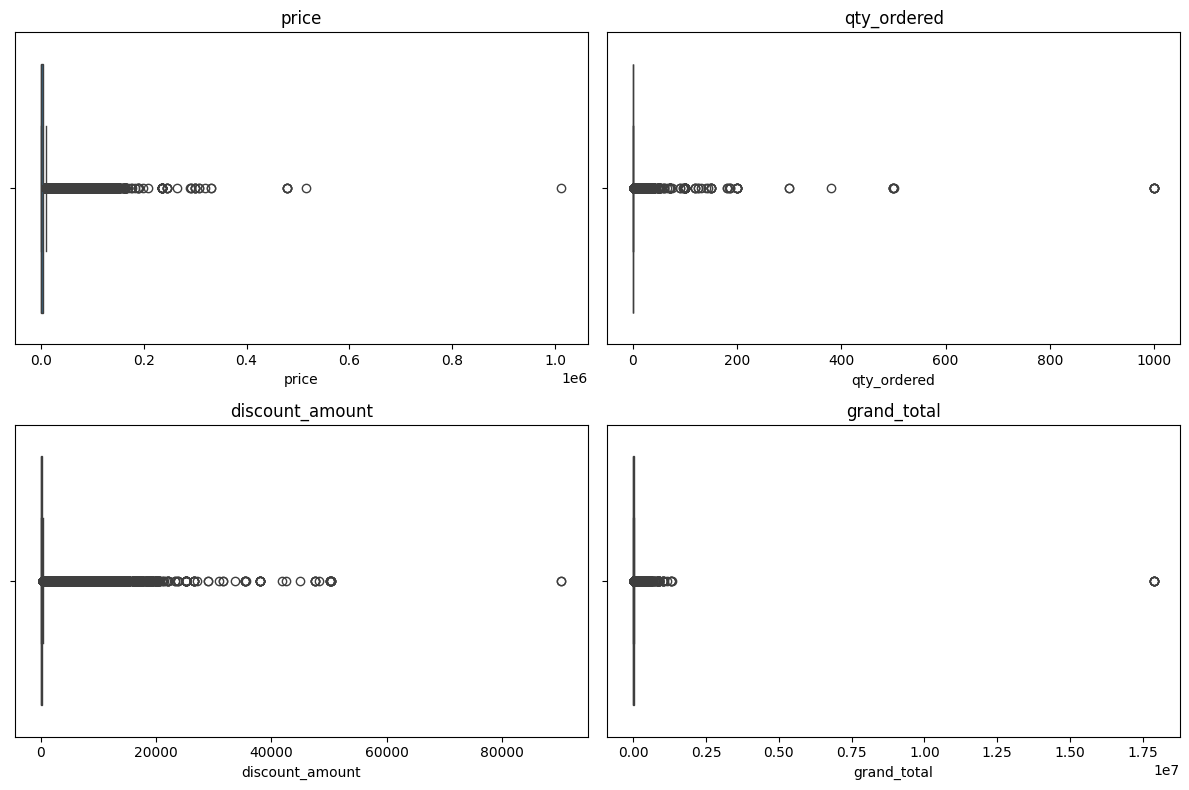

In [99]:
cols = ['price', 'qty_ordered', 'discount_amount', 'grand_total']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [100]:
#Outliers in grand_total, price and discount_amount bt3bar 3an legit high-value, bulk orders and huge discounts rather than errors. 
#I avoided capping since this data is important for analysis
#Only unreal data like -ve grand_total were fixed as they are outliears and impossible to happen.

In [101]:
df.columns

Index(['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered',
       'grand_total', 'increment_id', 'category_name_1', 'discount_amount',
       'payment_method', 'Working_Date', 'BI_Status', 'MV', 'Year', 'Month',
       'Customer_Since', 'M-Y', 'FY', 'Customer_ID'],
      dtype='object')

In [102]:
total = df.drop_duplicates(subset='increment_id')['grand_total'].sum()

In [103]:
total

np.float64(3928016742.036)

In [104]:
df['Price_per_product'] = (df['price'] * df['qty_ordered']) - df['discount_amount']

In [105]:
df['Price_per_product'].sum()

np.float64(3903020971.9627)

In [106]:
df['diff'] = df['Price_per_product'] - df['grand_total']

In [107]:
check = df.groupby('increment_id').agg(
    calculated_total=('Price_per_product', 'sum'),
    given_total=('grand_total', 'first')
)

check['diff'] = (
    check['calculated_total'] - check['given_total']
)

check.head()

,calculated_total,given_total,diff
increment_id,,,
100001290,332.0,332.0,0.0
100002382,999.0,1149.0,-150.0
100147444,240.0,240.0,0.0
100147445,2450.0,2450.0,0.0
100147446,60.0,60.0,0.0


In [108]:
check[check['diff'] != 0]

,calculated_total,given_total,diff
increment_id,,,
100002382,999.0,1149.0,-150.0
100147663,9013.0,1013.0,8000.0
100147714,350.0,165.0,185.0
100147782,1900.0,1100.0,800.0
100147840,1250.0,994.0,256.0
...,...,...,...
100562383,400.0,550.0,-150.0
100562384,499.0,649.0,-150.0
100562385,699.0,849.0,-150.0


In [109]:
df[df['increment_id'] == 100562305][
    ['price', 'qty_ordered', 'grand_total', 'discount_amount', 'MV']
].T

,584413,584414,584415,584416,584417,584418
price,96.0,48.0,145.0,275.0,189.0,49.0
qty_ordered,2,2,1,1,1,2
grand_total,326.01,326.01,326.01,326.01,326.01,326.01
discount_amount,299.99,299.99,299.99,299.99,299.99,299.99
MV,192,96,145,275,189,98


In [155]:
#Found out that there are some not add up to its grand_total and that made making a column for easier sql queries harder
#I can not just edit them since they probabaliy the legit number mabye their were operations done outside the csv file 

In [ ]:
#Solved it by keeping the grand_total for the first occurance for each order and replaced the other with zero

In [110]:
df['grand_total_dedup'] = df['grand_total'].where(
    ~df['increment_id'].duplicated(),
    0
)

In [111]:
df['grand_total_dedup'].sum()

np.float64(3928016742.0360003)

In [112]:
total

np.float64(3928016742.036)

In [113]:
df

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,discount_amount,...,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID,Price_per_product,diff,grand_total_dedup
1,211133,canceled,2016-07-01,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1,240.0,100147444,Beauty & Grooming,0.0,...,240,2016,7,2016-07,2016-07,FY17,2,240.0,0.0,240.0
2,211134,canceled,2016-07-01,Ego_UP0017-999-MR0,2450.0,1,2450.0,100147445,Women's Fashion,0.0,...,2450,2016,7,2016-07,2016-07,FY17,3,2450.0,0.0,2450.0
3,211135,complete,2016-07-01,kcc_krone deal,360.0,1,60.0,100147446,Beauty & Grooming,300.0,...,360,2016,7,2016-07,2016-07,FY17,4,60.0,0.0,60.0
4,211136,order_refunded,2016-07-01,BK7010400AG,555.0,2,1110.0,100147447,Soghaat,0.0,...,1110,2016,7,2016-07,2016-07,FY17,5,1110.0,0.0,1110.0
5,211137,canceled,2016-07-01,UK_Namkino All In One 200 Gms,80.0,1,80.0,100147448,Soghaat,0.0,...,80,2016,7,2016-07,2016-07,FY17,6,80.0,0.0,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
584519,905204,cod,2018-08-28,WOFSCE5AE00357AECDE,699.0,1,849.0,100562385,Women's Fashion,0.0,...,699,2018,8,2018-08,2018-08,FY19,115320,699.0,-150.0,849.0
584520,905205,processing,2018-08-28,MATHUA5AF70A7D1E50A,35599.0,1,35899.0,100562386,Mobiles & Tablets,0.0,...,35599,2018,8,2018-08,2018-08,FY19,115326,35599.0,-300.0,35899.0
584521,905206,processing,2018-08-28,MATSAM5B6D7208C6D30,129999.0,2,652178.0,100562387,Mobiles & Tablets,0.0,...,259998,2018,8,2018-07,2018-08,FY19,113474,259998.0,-392180.0,652178.0
584522,905207,processing,2018-08-28,MATSAM5B1509B4696EA,87300.0,2,652178.0,100562387,Mobiles & Tablets,0.0,...,174600,2018,8,2018-07,2018-08,FY19,113474,174600.0,-477578.0,0.0


In [114]:
df = df.drop(columns='Price_per_product')

In [115]:
df = df.drop(columns='diff')

In [116]:
df

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,discount_amount,...,Working_Date,BI_Status,MV,Year,Month,Customer_Since,M-Y,FY,Customer_ID,grand_total_dedup
1,211133,canceled,2016-07-01,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1,240.0,100147444,Beauty & Grooming,0.0,...,2016-07-01,Gross,240,2016,7,2016-07,2016-07,FY17,2,240.0
2,211134,canceled,2016-07-01,Ego_UP0017-999-MR0,2450.0,1,2450.0,100147445,Women's Fashion,0.0,...,2016-07-01,Gross,2450,2016,7,2016-07,2016-07,FY17,3,2450.0
3,211135,complete,2016-07-01,kcc_krone deal,360.0,1,60.0,100147446,Beauty & Grooming,300.0,...,2016-07-01,Net,360,2016,7,2016-07,2016-07,FY17,4,60.0
4,211136,order_refunded,2016-07-01,BK7010400AG,555.0,2,1110.0,100147447,Soghaat,0.0,...,2016-07-01,Valid,1110,2016,7,2016-07,2016-07,FY17,5,1110.0
5,211137,canceled,2016-07-01,UK_Namkino All In One 200 Gms,80.0,1,80.0,100147448,Soghaat,0.0,...,2016-07-01,Gross,80,2016,7,2016-07,2016-07,FY17,6,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
584519,905204,cod,2018-08-28,WOFSCE5AE00357AECDE,699.0,1,849.0,100562385,Women's Fashion,0.0,...,2018-08-28,Valid,699,2018,8,2018-08,2018-08,FY19,115320,849.0
584520,905205,processing,2018-08-28,MATHUA5AF70A7D1E50A,35599.0,1,35899.0,100562386,Mobiles & Tablets,0.0,...,2018-08-28,Gross,35599,2018,8,2018-08,2018-08,FY19,115326,35899.0
584521,905206,processing,2018-08-28,MATSAM5B6D7208C6D30,129999.0,2,652178.0,100562387,Mobiles & Tablets,0.0,...,2018-08-28,Gross,259998,2018,8,2018-07,2018-08,FY19,113474,652178.0
584522,905207,processing,2018-08-28,MATSAM5B1509B4696EA,87300.0,2,652178.0,100562387,Mobiles & Tablets,0.0,...,2018-08-28,Gross,174600,2018,8,2018-07,2018-08,FY19,113474,0.0


In [117]:
df.to_csv('df_cleaned.csv', index=False)

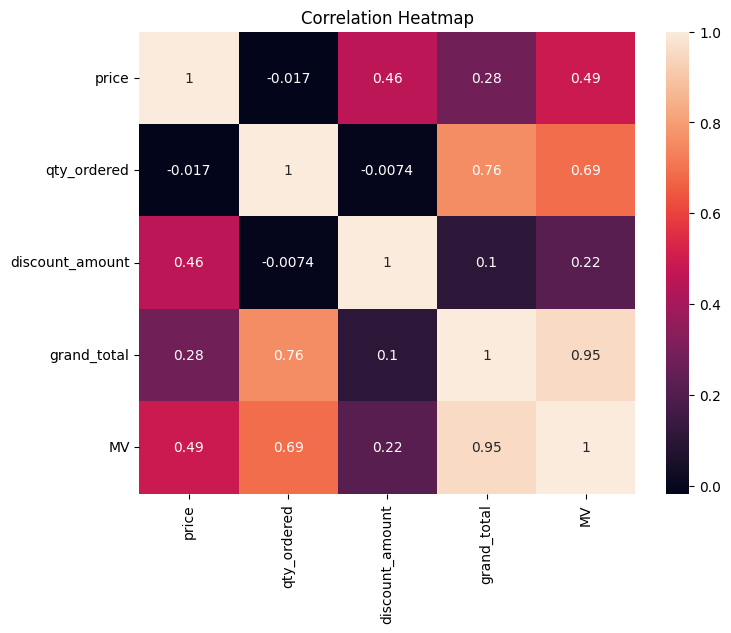

In [118]:
num_cols = ['price', 'qty_ordered', 'discount_amount', 'grand_total', 'MV']
corr = df[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap')
plt.show()

In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 582085 entries, 1 to 584523
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   item_id            582085 non-null  Int64         
 1   status             582085 non-null  object        
 2   created_at         582085 non-null  datetime64[ns]
 3   sku                582085 non-null  object        
 4   price              582085 non-null  float64       
 5   qty_ordered        582085 non-null  Int64         
 6   grand_total        582085 non-null  float64       
 7   increment_id       582085 non-null  Int64         
 8   category_name_1    582085 non-null  object        
 9   discount_amount    582085 non-null  float64       
 10  payment_method     582085 non-null  object        
 11  Working_Date       582085 non-null  datetime64[ns]
 12  BI_Status          582085 non-null  object        
 13  MV                 582085 non-null  Int64        

In [120]:
Most_cat_qyt = df.groupby('category_name_1')['qty_ordered'].sum().sort_values(ascending=False)

In [121]:
Most_cat_qyt

category_name_1
Mobiles & Tablets     132224
Men's Fashion         100269
Others                 84862
Superstore             82009
Women's Fashion        63902
Appliances             58101
Beauty & Grooming      53623
Soghaat                47405
Home & Living          29839
Entertainment          27411
Health & Sports        21419
Kids & Baby            18470
Computing              17203
Unknown                 9602
School & Education      4136
Books                   1354
Name: qty_ordered, dtype: Int64

In [122]:
figOne = px.bar(Most_cat_qyt, x=Most_cat_qyt.index, y=Most_cat_qyt.values, title='Total Quantity Ordered by Categories',
    labels={'x': 'Categories', 'y': 'Quantity Ordered'})
figOne.update_xaxes(tickangle=45)
figOne.show()

In [123]:
Top_cat_by_sales = df.groupby('category_name_1')['grand_total_dedup'].sum().sort_values(ascending=False)

In [124]:
Top_cat_by_sales

category_name_1
Mobiles & Tablets     2.172959e+09
Appliances            5.532705e+08
Entertainment         4.721214e+08
Computing             1.698449e+08
Others                1.662776e+08
Women's Fashion       1.046039e+08
Men's Fashion         9.197121e+07
Beauty & Grooming     4.152691e+07
Superstore            3.902877e+07
Unknown               3.288145e+07
Home & Living         3.276125e+07
Health & Sports       1.995749e+07
Soghaat               1.435105e+07
Kids & Baby           1.337718e+07
School & Education    2.037167e+06
Books                 1.047150e+06
Name: grand_total_dedup, dtype: float64

In [125]:
figTwo = px.bar(Top_cat_by_sales, x=Top_cat_by_sales.index, y=Top_cat_by_sales.values, title='Top Categories by Total Sales',
    labels={'x': 'Categories', 'y': 'Total sales'})
figTwo.update_xaxes(tickangle=45)
figTwo.show()

In [126]:
yearly_sales = df.groupby('Year')['grand_total_dedup'].sum().reset_index()

In [127]:
yearly_sales

,Year,grand_total_dedup
0,2016,5.135615e+08
1,2017,1.707923e+09
2,2018,1.706532e+09


In [128]:
figThree = px.bar(yearly_sales, x='Year', y='grand_total_dedup', title='Total Sales by Year', text_auto='.4s')
figThree.show()

In [129]:
yearly_orders = df.groupby('Year')['increment_id'].nunique().reset_index()

In [130]:
yearly_orders

,Year,increment_id
0,2016,107582
1,2017,185197
2,2018,114924


In [131]:
figFour = px.bar(yearly_orders, x='Year', y='increment_id', title='Total Orders by Year', text_auto='.4s')
figFour.show()

In [132]:
monthly_sales = (df.groupby('M-Y')['grand_total_dedup'].sum().sort_index())

In [133]:
monthly_sales

M-Y
2016-07    3.503882e+07
2016-08    4.266280e+07
2016-09    7.603174e+07
2016-10    7.547794e+07
2016-11    2.104241e+08
2016-12    7.392610e+07
2017-01    9.872073e+07
2017-02    6.934990e+07
2017-03    1.050406e+08
2017-04    1.176147e+08
2017-05    1.828799e+08
2017-06    1.159220e+08
2017-07    5.182261e+07
2017-08    8.704698e+07
2017-09    5.127128e+07
2017-10    9.766209e+07
2017-11    6.682763e+08
2017-12    6.231605e+07
2018-01    6.843494e+07
2018-02    2.714477e+08
2018-03    3.661127e+08
2018-04    8.318002e+07
2018-05    3.820819e+08
2018-06    2.044069e+08
2018-07    2.108151e+08
2018-08    1.200528e+08
Freq: M, Name: grand_total_dedup, dtype: float64

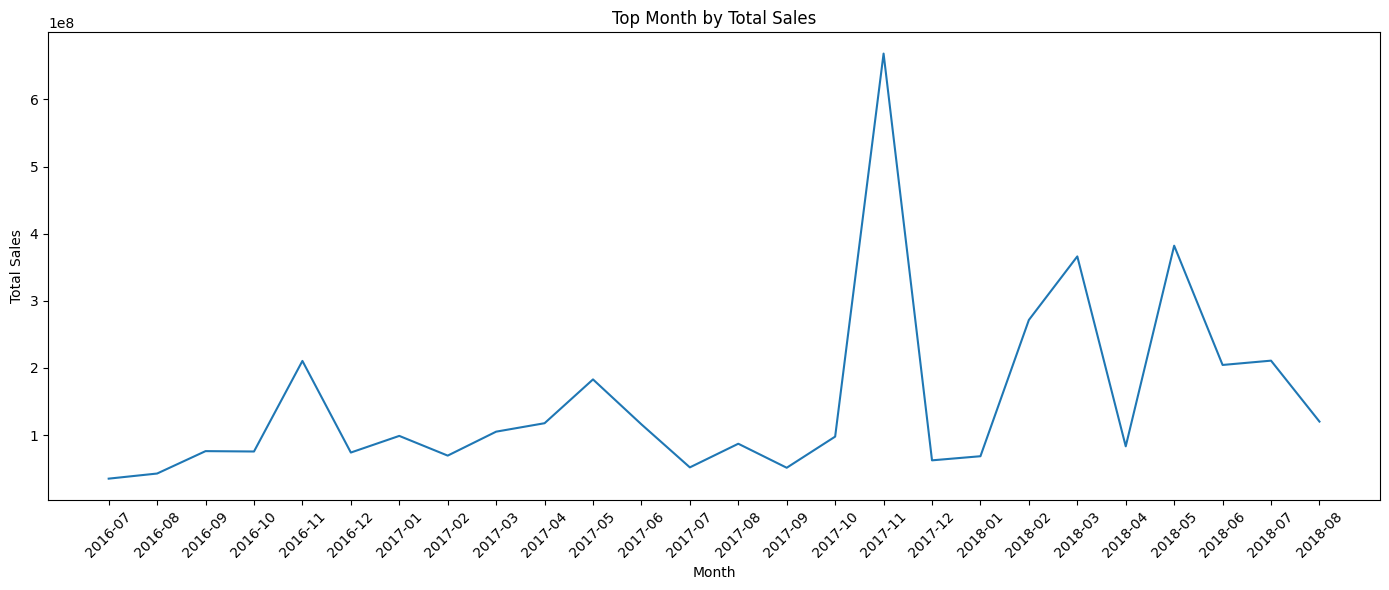

In [134]:
plt.figure(figsize=(14,6))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title('Top Month by Total Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [135]:
monthly_orders = (df.groupby('M-Y')['increment_id'].nunique().sort_index())

In [136]:
monthly_orders

M-Y
2016-07     7255
2016-08     9941
2016-09    13134
2016-10    10875
2016-11    55408
2016-12    10969
2017-01    10055
2017-02     8756
2017-03    13539
2017-04    12236
2017-05    20741
2017-06    10595
2017-07    10051
2017-08    13734
2017-09     5735
2017-10    12667
2017-11    57193
2017-12     9895
2018-01     8150
2018-02    19299
2018-03    35028
2018-04     7696
2018-05    19846
2018-06     9604
2018-07     7481
2018-08     7820
Freq: M, Name: increment_id, dtype: int64

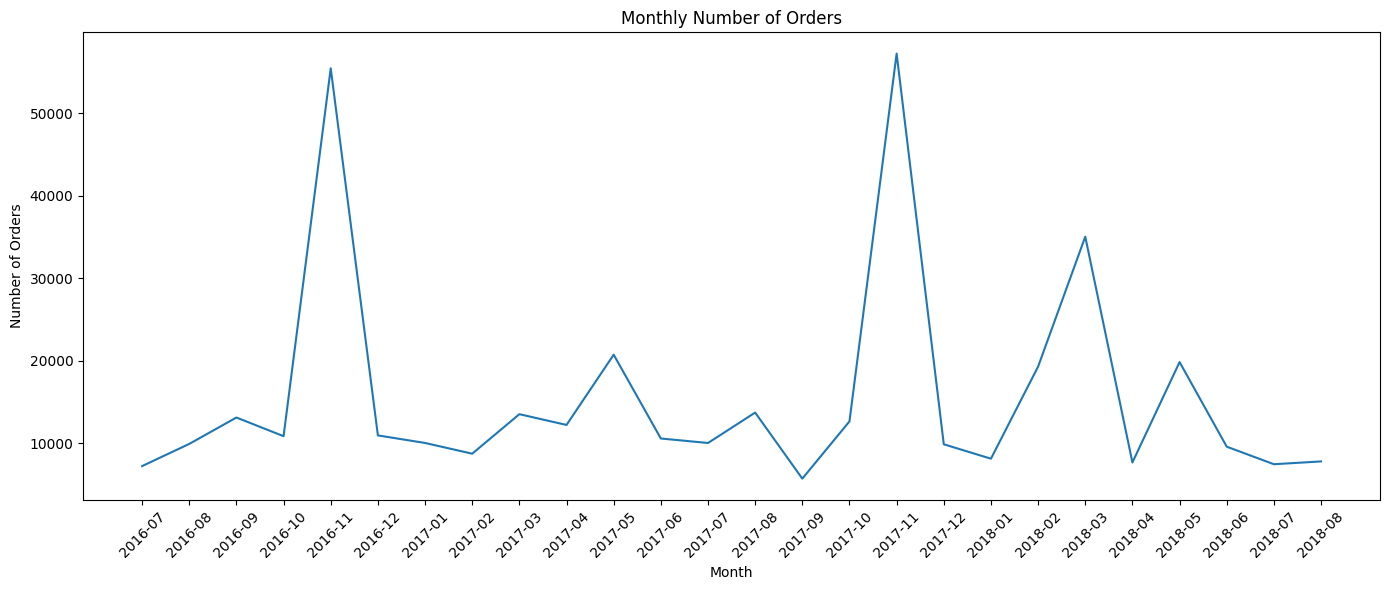

In [137]:
plt.figure(figsize=(14,6))

plt.plot(monthly_orders.index.astype(str), monthly_orders.values)

plt.title('Monthly Number of Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [138]:
Top_customers = df.groupby('Customer_ID')['grand_total_dedup'].sum().sort_values(ascending=False).head(10)

In [139]:
Top_customers

Customer_ID
5032      36182288.45
109038    19798066.57
50387     17888000.00
110215    17528644.00
113694    16201928.24
39707     16124394.72
10654     15915258.00
111057    15185306.00
26527     11350893.00
11305     11140251.76
Name: grand_total_dedup, dtype: float64

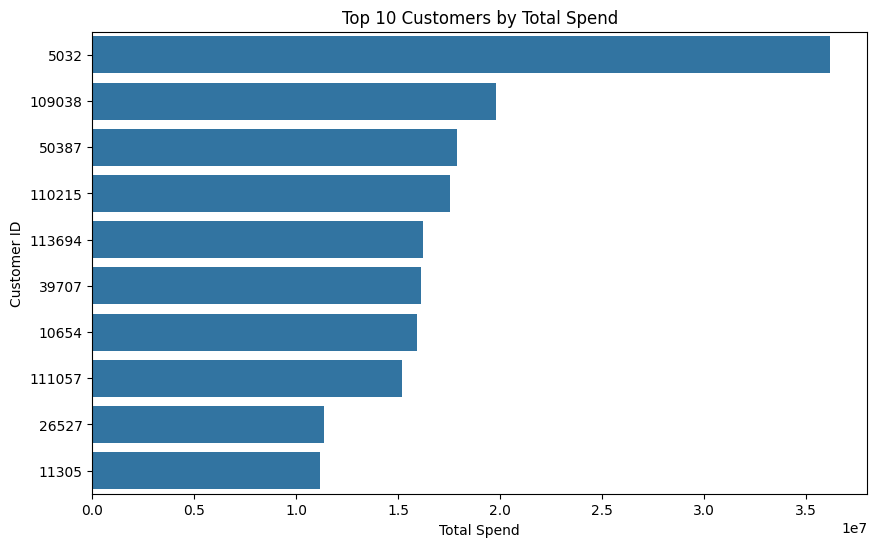

In [140]:
plt.figure(figsize=(10,6))
sns.barplot(x=Top_customers.values, y=Top_customers.index.astype(int).astype(str))
plt.title('Top 10 Customers by Total Spend')
plt.xlabel('Total Spend')
plt.ylabel('Customer ID')
plt.show()

In [141]:
payment_sales = (
    df.groupby('payment_method')['grand_total_dedup']
    .sum()
    .sort_values(ascending=False)
)

payment_sales

payment_method
Payaxis              9.027979e+08
Easypay              7.470625e+08
cod                  7.267306e+08
bankalfalah          5.379408e+08
easypay_voucher      5.277152e+08
jazzvoucher          1.958044e+08
jazzwallet           1.061466e+08
Easypay_MA           8.910841e+07
customercredit       3.130769e+07
apg                  1.922688e+07
ublcreditcard        1.853722e+07
mygateway            1.107194e+07
mcblite              6.017631e+06
internetbanking      4.313241e+06
cashatdoorstep       2.949700e+06
financesettlement    8.657410e+05
marketingexpense     2.293010e+05
productcredit        1.910540e+05
Name: grand_total_dedup, dtype: float64

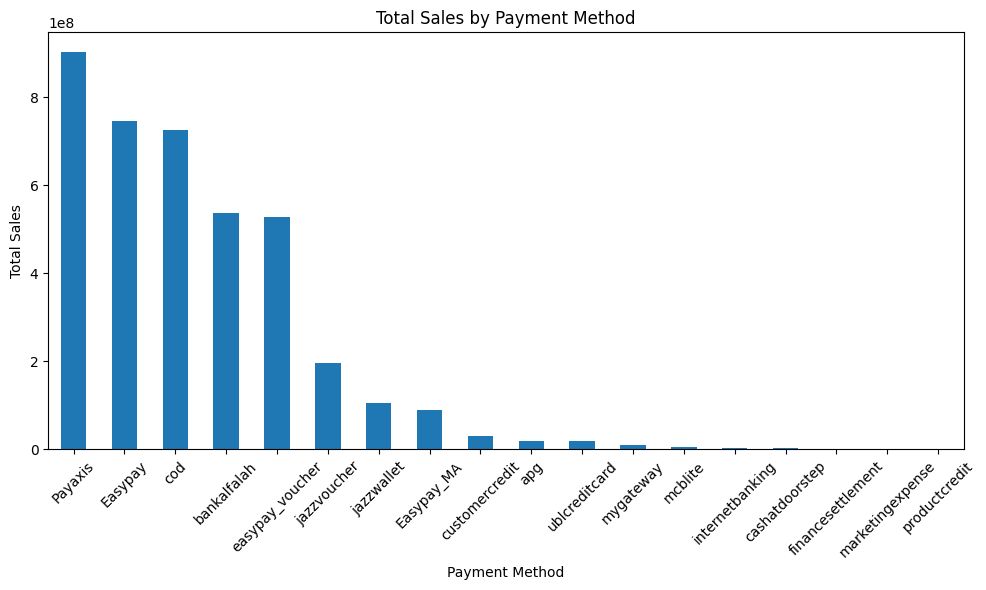

In [142]:
plt.figure(figsize=(10,6))

payment_sales.plot(kind='bar')

plt.title('Total Sales by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [143]:
payment_orders = (
    df.groupby('payment_method')['increment_id']
    .nunique()
    .sort_values(ascending=False)
)

payment_orders

payment_method
cod                  181448
Payaxis               67904
Easypay               60261
easypay_voucher       27490
jazzwallet            21607
bankalfalah           16898
jazzvoucher           12804
Easypay_MA            10041
customercredit         5116
apg                    1239
ublcreditcard           696
mcblite                 686
cashatdoorstep          644
mygateway               373
internetbanking         344
productcredit           100
marketingexpense         42
financesettlement        10
Name: increment_id, dtype: int64

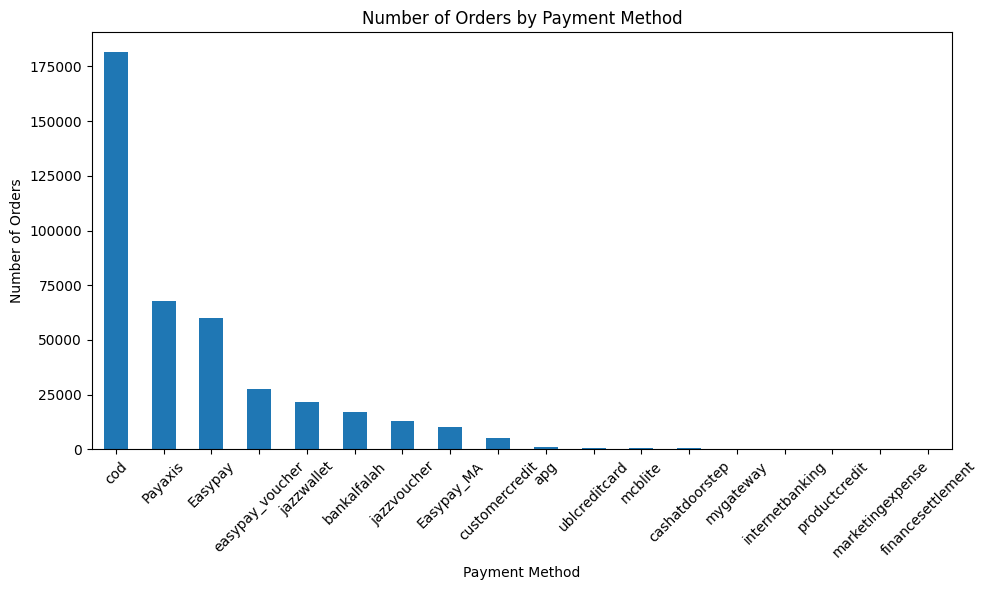

In [144]:
plt.figure(figsize=(10,6))

payment_orders.plot(kind='bar')

plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [145]:
top_products_qty = (
    df.groupby('sku')['qty_ordered']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_qty

sku
OTHOTH5A0945D0A72F4              6842
VIT5ABCCF7FDF973                 3914
IDROID_BALRX7-Gold               3907
MATSAM59DB75ADB2F80              3791
IDROID_BALRX7-Jet black          3038
Al Muhafiz Sohan Halwa Almond    2685
KNO59D64DAF36939                 2489
emart_00-7                       2397
infinix_Zero 4-Grey              2191
kcc_krone deal                   2131
Name: qty_ordered, dtype: Int64

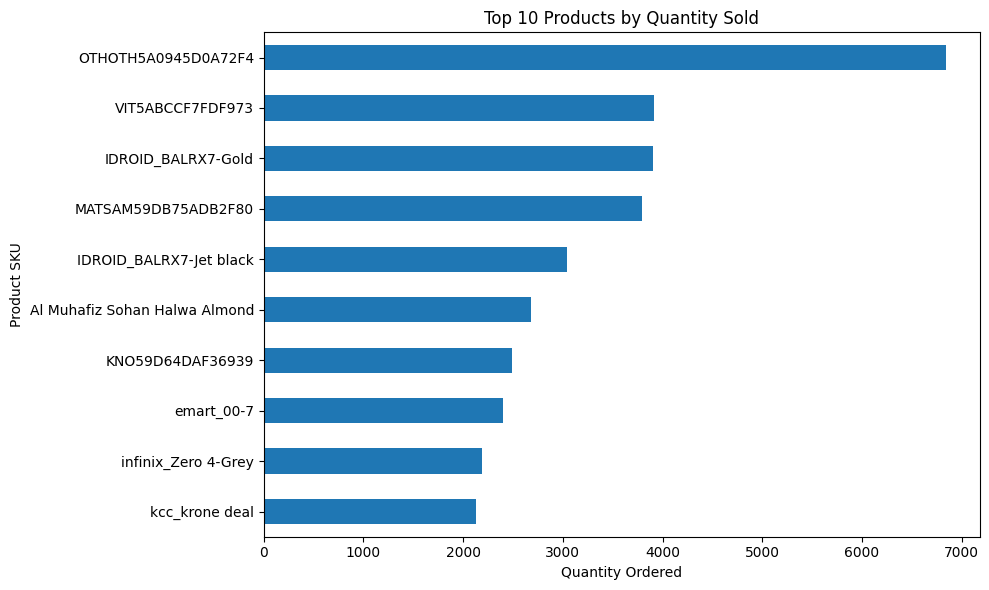

In [146]:
plt.figure(figsize=(10,6))

top_products_qty.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity Ordered')
plt.ylabel('Product SKU')

plt.tight_layout()
plt.show()

In [147]:
top_products_sales = (
    df.groupby('sku')['grand_total_dedup']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_sales

sku
MATSAM5B10F7E2AC8C1             81408215.00
MATSAM59DB757FB47A2             80417811.00
infinix_Zero 4-Grey             48754215.66
IDROID_BALRX7-Gold              43793777.00
MATSAM59DB75ADB2F80             43583529.48
iphone-7-32gb-wof-Matt Black    30200141.00
MATSAM5B1509B4696EA             30017396.00
MATSAM5B10F91A9B6AB             29388276.00
MATSAM59D74470AD085             28071202.00
MATSAM5B10F2272EBD9             26651812.00
Name: grand_total_dedup, dtype: float64

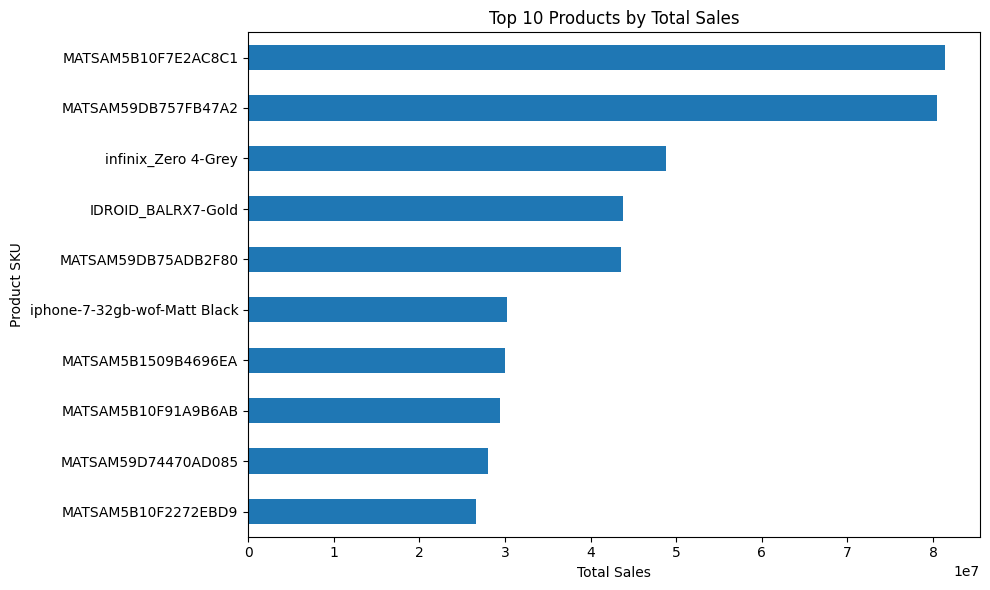

In [148]:
plt.figure(figsize=(10,6))

top_products_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product SKU')

plt.tight_layout()
plt.show()